# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [67]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'asteves2'   # <-- set this
d = np.genfromtxt(f'/Users/andrewsteves/ast457_2026_Fall/labs/07/data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

286 epochs over 969 days; median quoted error 0.039 mag; rms of the light curve 0.228 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


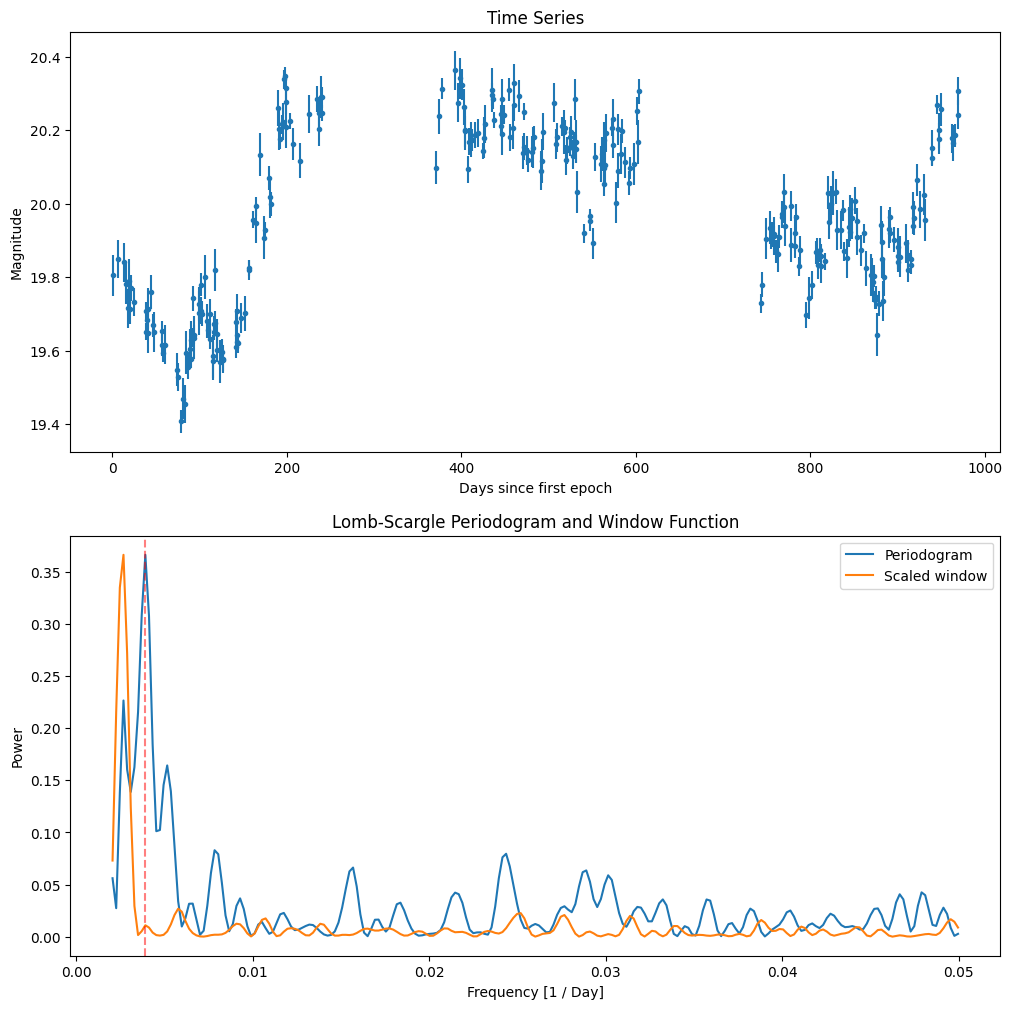

Period of highest peak: 255.004 days
False alarm probability: 4.469e-26


In [68]:
# Part 1: your work here

T = t.max() - t.min()

LS = LombScargle(t = t, y = y, dy = e)
f, p = LS.autopower(minimum_frequency = 1 / (T / 2), maximum_frequency = 1 / 20, samples_per_peak = 5)
false_alarm_prob = LS.false_alarm_probability(power = p.max(), minimum_frequency = 1 / (T / 2), maximum_frequency = 1 / 20, samples_per_peak = 5)

LS_window = LombScargle(t = t, y = np.ones_like(y), fit_mean = False, center_data = False)
pw = LS_window.power(f)

hi_peak_idx = np.argmax(p)
peak_f, peak_p = f[hi_peak_idx], p[hi_peak_idx]

fig, ax = plt.subplots(nrows = 2, ncols = 1, figsize = (12, 12))

ax[0].errorbar(t, y, yerr = e, marker = '.', linestyle = 'None')

ax[0].set_xlabel('Days since first epoch')
ax[0].set_ylabel('Magnitude')
ax[0].set_title('Time Series')

ax[1].plot(f, p, label = 'Periodogram')
ax[1].plot(f, pw * p.max() / pw.max(), label = 'Scaled window')
ax[1].axvline(peak_f, linestyle = '--', color = 'red', alpha = 0.5)

ax[1].set_xlabel('Frequency [1 / Day]')
ax[1].set_ylabel('Power')
ax[1].set_title('Lomb-Scargle Periodogram and Window Function')
ax[1].legend()

plt.show()

print(f'Period of highest peak: {1 / peak_f:.3f} days')
print(f'False alarm probability: {false_alarm_prob:.3e}')

**ANSWER (a few sentences):**

The highest peak period is roughly 255 days with a false alarm probability of $4.469\times10^{-26}$, where the false alarm probability function assumes the baluev noise model. It is very likely that the highest peak is an alias because it occurs during an unsampled period of the time series shown. Other aliases are likely to occur during the frequencies corresponding to days ~250-375 and ~600-750 because there are no observations in these time ranges. Intervals less than $T/2$ likely isn't useful there isn't enough samples to claim that the data is periodic in nature.

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ 0.371 (+0.470 / −0.136) mag, $\tau = $ 290.894 (+1207.351 / −178.466) d, $T/\tau = $ 9.29; the exponential kernel beats the squared exponential by $\Delta\ln L = $ 35.50; 27 of 50 held-out points are inside the 68% band.


In [143]:
# Part 2: your work here

def lnL(theta, t, y, e):
    mu, ln_sig, ln_tau = theta
    sig, tau = np.exp(ln_sig), np.exp(ln_tau)
    dt = np.abs(t[:, None] - t[None, :])
    C = sig**2 * np.exp(-dt / tau) + np.diag(e**2)
    cf = cho_factor(C, lower = True)                #Calculates (y-mu)^T C^-1 * (y-mu)
    r = (y - mu) @ cho_solve(cf, y - mu)

    detLnC = 2 * np.sum(np.log(np.diag(cf[0])))

    return -0.5 * (r + detLnC + t.size * np.log(2 * np.pi))

def logPrior(theta):
    mu, ln_sig, ln_tau = theta

    if np.log(0.01) < ln_sig < np.log(3) and np.log(10) < ln_tau < np.log(4000):
        return 0.0
    else:
        return -np.inf

def logPost(theta, t, y, e):
    lp = logPrior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnL(theta, t, y, e)

In [158]:
neg = lambda th: -logPost(th, t, y, e)
starts = [[y.mean(), np.log(y.std()), np.log(tau0)] for tau0 in (20, 100, 1000, 2000)]

fits = []

for s in starts:
    r = minimize(neg, s, method = 'Nelder-Mead', options={'xatol': 1e-4, 'fatol': 1e-4, 'maxiter': 5000})
    fits.append(r)

best = min(fits, key = lambda x: x.fun)
theta_ml = best.x

ndim, nwalkers, nsteps = 3, 32, 5000
p0 = theta_ml + 1e-3 * np.random.default_rng(42).normal(size = (nwalkers, ndim))

sampler = emcee.EnsembleSampler(nwalkers, ndim, logPost, args = (t, y, e))
sampler.run_mcmc(p0, nsteps)

tau_ac = sampler.get_autocorr_time(tol = 0)
burn = int(5 * tau_ac.max())
chain = sampler.get_chain(discard=burn, thin = max(1, int(tau_ac.max() / 2)), flat = True)

print('autocorrelation times:', tau_ac, '  need nsteps >', 50 * tau_ac.max())
print('mean acceptance fraction:', sampler.acceptance_fraction.mean())
for name, s in [('sigma [mag]', np.exp(chain[:, 1])), ('tau [d]', np.exp(chain[:, 2]))]:
    lo, med, hi = np.percentile(s, [16, 50, 84])
    print(f'{name}: {med:.3f}  +{hi - med:.3f} / -{med - lo:.3f}')

tau_samples = np.exp(chain[:, 2])                  # DRW tau in days, from your exponential-kernel emcee chain
lo, med, hi = np.percentile(tau_samples, [16, 50, 84])
print(f'T/tau (median): {T / med:.2f}   68% range: {T / hi:.2f} to {T / lo:.2f}')
print(f'T/tau (ML):     {T / np.exp(theta_ml[2]):.2f}')

autocorrelation times: [51.94978397 61.04564185 61.73103679]   need nsteps > 3086.5518393381512
mean acceptance fraction: 0.5936125
sigma [mag]: 0.371  +0.470 / -0.136
tau [d]: 290.894  +1207.351 / -178.466
T/tau (median): 3.33   68% range: 0.65 to 8.62
T/tau (ML):     9.29


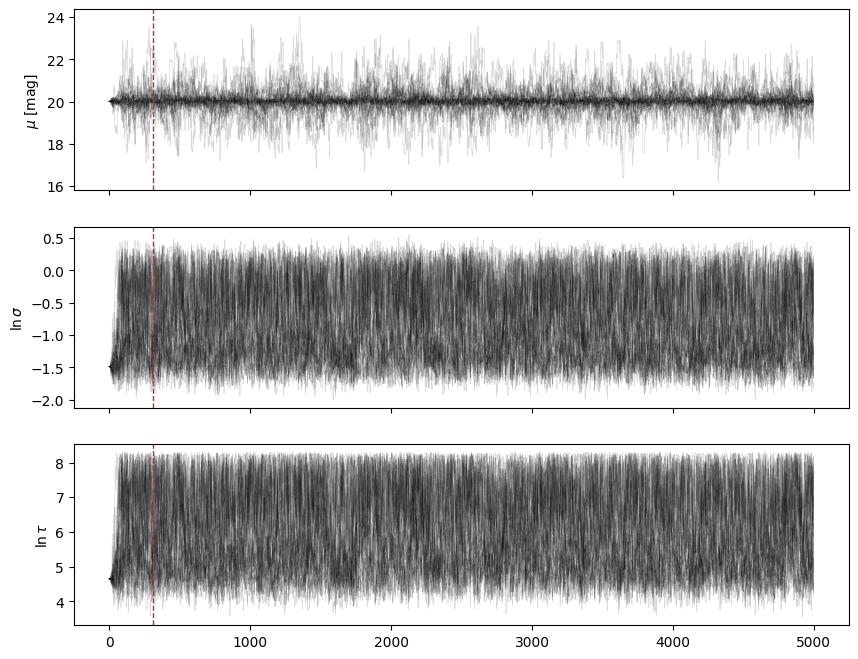

In [145]:
samples = sampler.get_chain()
labels = [r'$\mu$ [mag]', r'$\ln\sigma$', r'$\ln\tau$']

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(samples[:, :, i], color='k', alpha=0.15, lw=0.5)
    ax.axvline(burn, color='C3', ls='--', lw=1, label='end of burn-in')
    ax.set_ylabel(labels[i])

In [156]:
# Squared exponential kernel
def lnL_kernel(theta, t, y, e):
    mu, ln_sig, ln_tau = theta
    sig, tau = np.exp(ln_sig), np.exp(ln_tau)
    dt = np.abs(t[:, None] - t[None, :])
    C = sig**2 * np.exp(-dt**2 / (2 * tau**2)) + np.diag(e**2)
    cf = cho_factor(C, lower = True)                #Calculates (y-mu)^T C^-1 * (y-mu)
    r = (y - mu) @ cho_solve(cf, y - mu)

    detLnC = 2 * np.sum(np.log(np.diag(cf[0])))

    return -0.5 * (r + detLnC + t.size * np.log(2 * np.pi))

def logPost_se(theta, t, y, e):
    lp = logPrior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnL_kernel(theta, t, y, e)

neg_se = lambda th: -logPost_se(th, t, y, e)
starts = [[y.mean(), np.log(y.std()), np.log(tau0)] for tau0 in (20, 100, 1000, 2000)]

fits_exp = []

for s in starts:
    r = minimize(neg_se, s, method = 'Nelder-Mead', options={'xatol': 1e-4, 'fatol': 1e-4, 'maxiter': 5000})
    fits_exp.append(r)

best_se = min(fits_exp, key = lambda x: x.fun)
theta_ml_exp = best_se.x

print(f'Best parameters: {theta_ml_exp}')
print(f'max lnL: exponential {-best.fun:.2f}, squared exponential {-best_se.fun:.2f}, '
      f'difference = {(-best.fun) - (-best_se.fun):.2f}')

Best parameters: [19.98956241 -1.63137047  2.41364153]
max lnL: exponential 371.35, squared exponential 335.85, difference = 35.50


In [157]:
ndim, nwalkers, nsteps = 3, 32, 5000
p0_se = theta_ml_exp + 1e-3 * np.random.default_rng(42).normal(size = (nwalkers, ndim))

sampler_se = emcee.EnsembleSampler(nwalkers, ndim, logPost, args = (t, y, e))
sampler_se.run_mcmc(p0_se, nsteps)

tau_ac_se = sampler.get_autocorr_time(tol = 0)
burn_exp = int(5 * tau_ac_se.max())
chain_se = sampler_se.get_chain(discard = burn_exp, thin = max(1, int(tau_ac_se.max() / 2)), flat = True)

print('autocorrelation times:', tau_ac_se, '  need nsteps >', 50 * tau_ac_se.max())
print('mean acceptance fraction:', sampler_se.acceptance_fraction.mean())
for name, s in [('sigma [mag]', np.exp(chain_se[:, 1])), ('tau [d]', np.exp(chain_se[:, 2]))]:
    lo, med, hi = np.percentile(s, [16, 50, 84])
    print(f'{name}: {med:.3f}  +{hi - med:.3f} / -{med - lo:.3f}')

autocorrelation times: [51.94978397 61.04564185 61.73103679]   need nsteps > 3086.5518393381512
mean acceptance fraction: 0.5911125000000002
sigma [mag]: 0.381  +0.448 / -0.148
tau [d]: 304.708  +1201.825 / -191.970


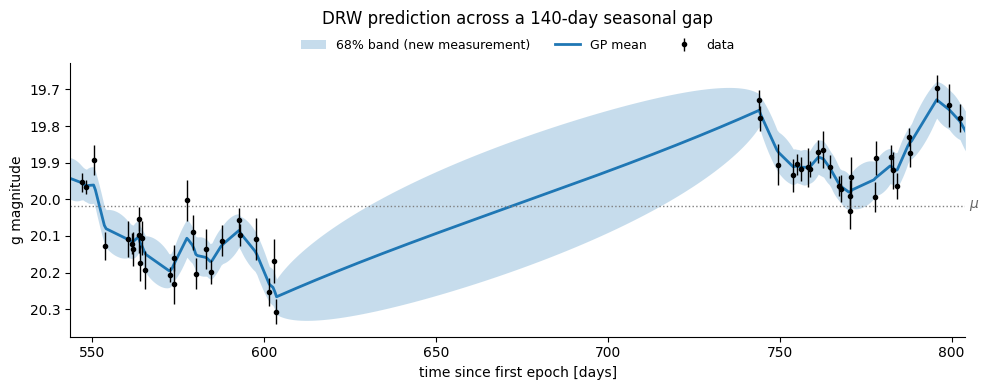

In [163]:
def k_exp(a, b, sig, tau):
    return sig**2 * np.exp(-np.abs(a[:, None] - b[None, :]) / tau)

def gp_predict(t_new, t, y, e, theta):
    mu, sig, tau = theta[0], np.exp(theta[1]), np.exp(theta[2])

    dt = np.abs(t[:, None] - t[None, :])
    C = sig**2 * np.exp(-dt / tau) + np.diag(e**2)
    cf = cho_factor(C, lower = True)

    dt_cross = np.abs(t_new[:, None] - t[None, :])
    Ks = sig**2 * np.exp(-dt_cross / tau)

    mean = mu + Ks @ cho_solve(cf, y - mu)
    var = sig**2 - np.sum(Ks * cho_solve(cf, Ks.T).T, axis = 1)

    return mean, np.sqrt(np.clip(var, 0, None))

gaps = np.diff(t)
k = np.argmax(gaps)
t_lo, t_hi = t[k] - 60, t[k + 1] + 60
tg = np.linspace(t_lo, t_hi, 500)

m, sd_latent = gp_predict(tg, t, y, e, theta_ml)
sd_meas = np.sqrt(sd_latent**2 + np.median(e)**2)

band = sd_meas                                  # or sd_latent: choose one, and say which in your write-up
band_label = '68% band (new measurement)'       # change to match if you switch

w = (t > t_lo) & (t < t_hi)
fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(tg, m - band, m + band, color='C0', alpha=0.25, lw=0, label=band_label)
ax.plot(tg, m, color='C0', lw=2, label='GP mean')
ax.errorbar(t[w], y[w], e[w], fmt='o', color='k', ms=3, lw=1, label='data')
ax.axhline(theta_ml[0], color='0.5', ls=':', lw=1)
ax.text(t_hi, theta_ml[0], r' $\mu$', va='center', color='0.4')

ax.set_xlim(t_lo, t_hi)
ax.invert_yaxis()                               # brighter = up
ax.set_xlabel('time since first epoch [days]')
ax.set_ylabel('g magnitude')
ax.set_title(f'DRW prediction across a {gaps[k]:.0f}-day seasonal gap', pad=28)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False, fontsize=9)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

In [180]:
#Held out blocks for both kernels

def cov(t1, t2, sig, scale, kind):
    dt = np.abs(t1[:, None] - t2[None, :])

    if kind == 'exp':
        return sig**2 * np.exp(-dt / scale)
    if kind == 'se':
        return sig**2 * np.exp(-dt**2 / (2 * scale**2))

def neg_lnL(theta, t, y, e, kind):
    mu, sig, scale = theta[0], np.exp(theta[1]), np.exp(theta[2])
    if not (0.01 < sig < 3 and 10 < scale < 4000):
        return np.inf
    cf = cho_factor(cov(t, t, sig, scale, kind) + np.diag(e**2), lower = True)

    return 0.5 * ((y - mu) @ cho_solve(cf, y - mu) + 2 * np.log(np.diag(cf[0])).sum() + t.size * np.log(2 * np.pi))

season = np.cumsum(np.r_[0, np.diff(t) > 60])
season_end = np.array([t[season == s].max() for s in season])
rng = np.random.default_rng(42)

while True:
    i = np.sort(rng.choice(t.size, 4, replace = False))
    b = t[i]
    if np.all(b + 30 <= season_end[i]) and np.all(np.diff(b) >= 30 + 60):
        break

test = np.any([(t >= x) & (t < x + 30) for x in b], axis=0)
tr = ~test

for kind in ('exp', 'se'):
    th = minimize(neg_lnL, [y[tr].mean(), np.log(y[tr].std()), np.log(100)], args = (t[tr], y[tr], e[tr], kind), method = 'Nelder-Mead').x
    mu, sig, scale = th[0], np.exp(th[1]), np.exp(th[2])
    cf = cho_factor(cov(t[tr], t[tr], sig, scale, kind) + np.diag(e[tr]**2), lower = True)
    Ks = cov(t[test], t[tr], sig, scale, kind)
    pred = mu + Ks @ cho_solve(cf, y[tr] - mu)
    band = np.sqrt(sig**2 - np.sum(Ks * cho_solve(cf, Ks.T).T, axis = 1) + e[test]**2)
    inside = inside = np.mean(np.abs(y[test] - pred) < band)
    R2 = 1 - np.sum((y[test] - pred)**2) / np.sum((y[test] - y[tr].mean())**2)
    print(f'{kind}: held out {test.sum()}, inside 68% band {inside:.0%}, R^2 = {R2:.3f}')

exp: held out 50, inside 68% band 54%, R^2 = 0.230
se: held out 50, inside 68% band 76%, R^2 = 0.512


**FINAL ANSWER:**

From the data, the accurate values of $\sigma$ and $\tau$ are unknown, but may lie in a wide range of values based on the light curve. Because of this, the log priors are used for both parameters to allow for significant differences in order of magnitude. After running the MCMC, I obtained values of $\sigma = 0.371^{+0.470}_{-0.136}$, $\tau = 290.894 ^{+1207.351}_{-178.466}$. Convergence was obtained with the auto correlation, where in the trace plots of all three parameters settle around a constant value. From the analysis, the exponential likelihood is greater than the squared exponential likelihood by about 35.5 orders of magnitude. The difference in likelihood means that the light curve of the quasar is not smooth, rather having lots of sharp peaks and valleys. The exponential model returned $\sigma = 0.381^{+0.448}_{-0.148}$, $\tau = 304.708 ^{+1201.825}_{-191.970}$. Because the exponential returned a better likelihood on the same data, those values for $\sigma$ and $\tau$ have been chosen. From the (AI generated) plot, the band is for a new measurement because it is the sum of the true light curve and one typical measurement error $(\sqrt{\sigma^{2}_{latent}+median(e^{2}}))$. About 54% of the hidden points from the exponential model land within the exponential kernal, and 76% for the squared exponential kernel.

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


In [ ]:
# Part 3: your work here

**ANSWER (the decision rule first, then the verdict):**

*your answer goes here*

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


In [ ]:
# Part 4: your work here

**REFEREE REPORT:**

*your report goes here*

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [ ]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


In [ ]:
# Part 5: your work here

**ANSWER (the criterion first, then the result):**

*your answer goes here*

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

*your answer goes here*

**REFLECTION:**

*your answer goes here*

**VERIFICATION PLAN:**

*your plan goes here*